In [46]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

plt.rcParams['figure.figsize'] = (12,8)
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 12

In [ ]:
G = nx.read_edgelist('graph.edgelist')

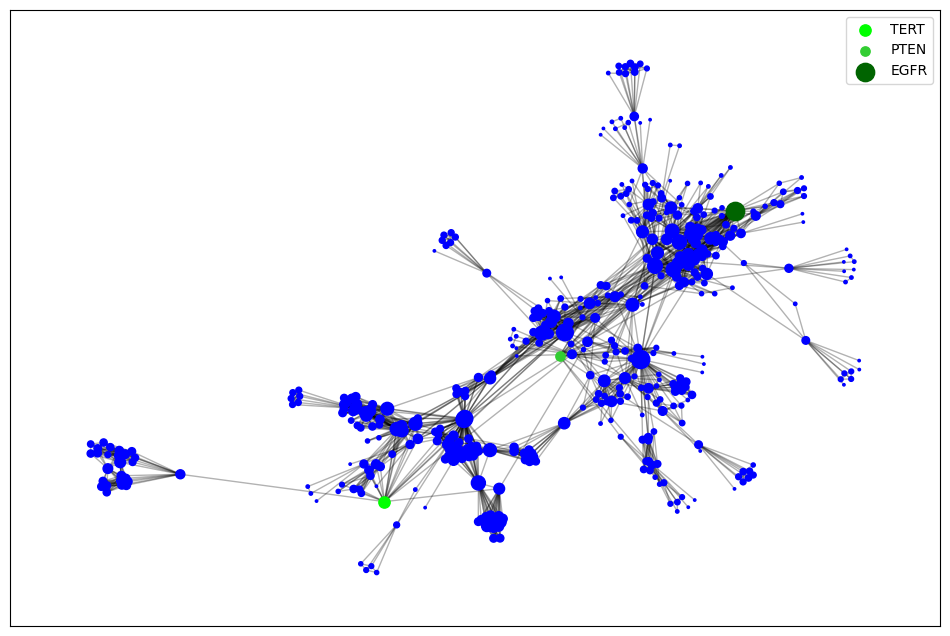

In [31]:
sementes = ['TERT', 'PTEN', 'EGFR']
sem_sementes = list(set(G.nodes) - set(sementes))
cores = ['lime', 'limegreen', 'darkgreen']
pos_iniciais = {no: (0+i*10, 0+i*10) for i, no in enumerate(sementes)}

pos = nx.spring_layout(G, pos=pos_iniciais, fixed=sementes, seed=42, k=0.8)

for semente, cor in list(zip(sementes, cores)):
    nx.draw_networkx_nodes(G, pos, nodelist=[semente], node_color=cor, node_size=G.degree(semente)*3, label=semente).set_zorder(3)

nx.draw_networkx_edges(G, pos, alpha=0.3)
nx.draw_networkx_nodes(G, pos, nodelist=sem_sementes, node_color='blue', node_size=list(map(lambda x: x[1]*3, G.degree(sem_sementes))))

plt.legend()
plt.savefig("grafo_customizado.png", format="PNG", dpi=300)

plt.show()

### Estrutura da rede

In [32]:
print('Número de vértices: ', G.number_of_nodes())
print('Número de arestas: ', G.number_of_edges())
if not nx.is_connected(G):
    print('Número de componentes conectadas: ', nx.number_connected_components(G))
    print('Número de isolados: ', len(list(nx.isolates(G))))
else:
    print('Rede conectada: Sim')

Número de vértices:  449
Número de arestas:  2127
Rede conectada: Sim


## Métricas globais

Densidade:  0.021


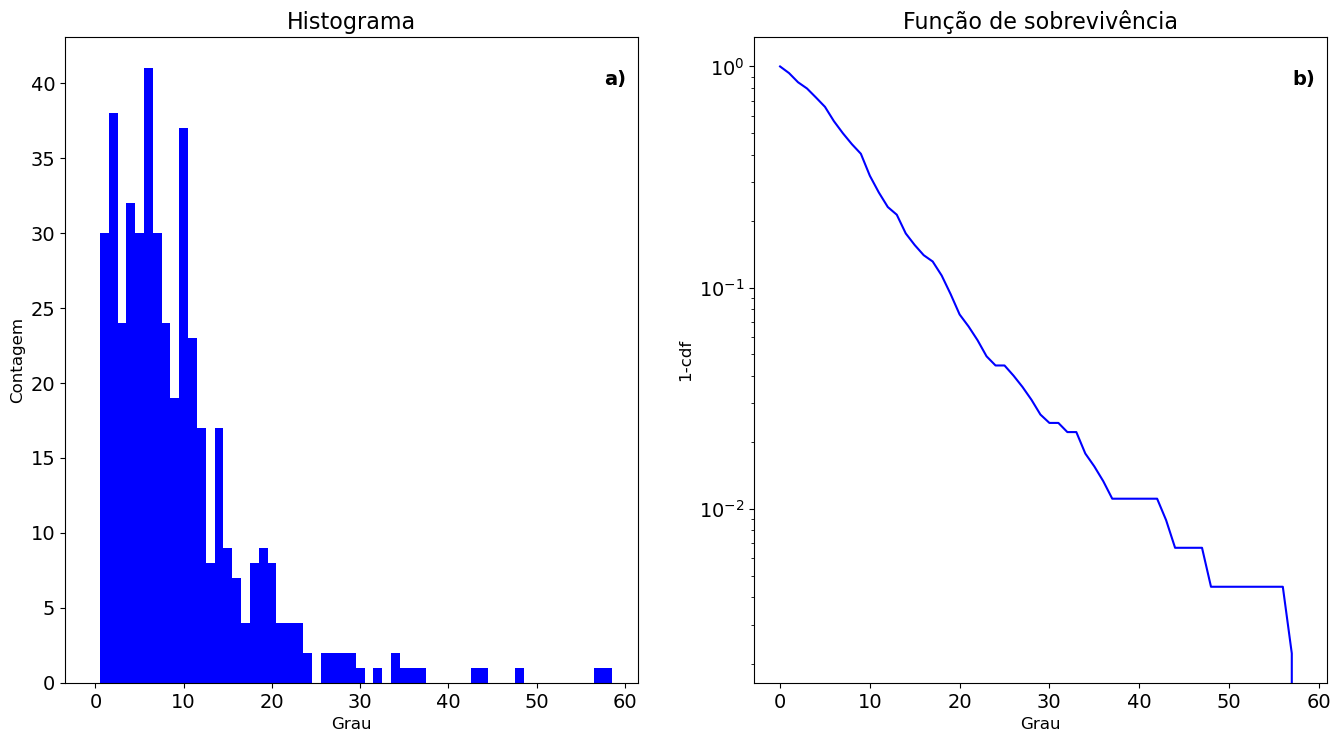

In [81]:
print(f'Densidade: {nx.density(G): .3f}')
fig, axs = plt.subplots(1,2, figsize=(14,8))

hist = nx.degree_histogram(G)
degrees = np.array(range(len(hist)))

axs[0].bar(degrees, hist, color='blue', width=1.0)
axs[0].set_title('Histograma')
axs[0].set_xlabel('Grau')
axs[0].set_ylabel('Contagem')
axs[0].text(0.98, 0.95, 'a)', 
        transform=axs[0].transAxes, 
        va='top', ha='right', 
        fontsize=14,
        fontweight='bold')
cumhist = 1-np.cumsum(hist)/np.sum(hist)
axs[1].semilogy(degrees, cumhist, color='blue')
axs[1].set_title('Função de sobrevivência')
axs[1].set_xlabel('Grau')
axs[1].set_ylabel('1-cdf')
axs[1].text(0.98, 0.95, 'b)', 
        transform=axs[1].transAxes, 
        va='top', ha='right', 
        fontsize=14,
        fontweight='bold')

plt.tight_layout(pad=2)
plt.savefig('dist_graus.png',format="PNG", dpi=300)
plt.show()

**Diâmetro:** Definido pela maior excentricidade entre todos os vértices

**Raio:** Definido pela menor excentricidade entre todos os vértices

In [58]:
print(f'Diâmetro: {nx.diameter(G):.3f}')
print(f'Raio: {nx.radius(G):.3f}')

Diâmetro: 8.000
Raio: 4.000


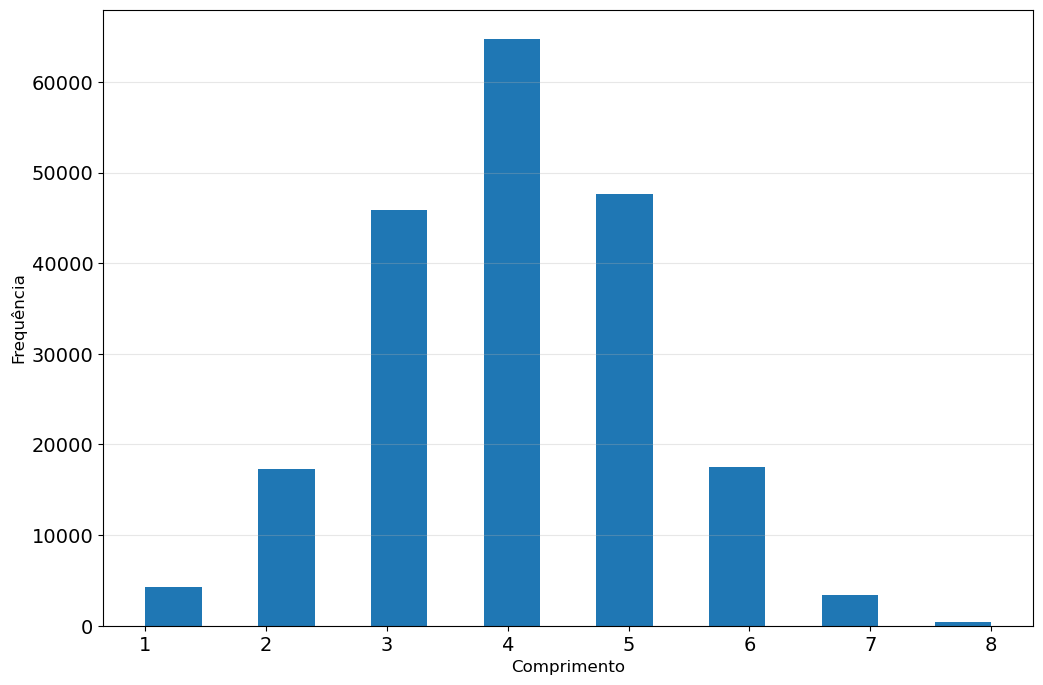

In [83]:
n = nx.number_of_nodes(G)
nos = list(G.nodes)
dist_matrix = np.full((n, n), np.inf)
np.fill_diagonal(dist_matrix, 0)

for origem, dist in nx.all_pairs_shortest_path_length(G):
    for destino, comprimento in dist.items():
        pos_origem = nos.index(origem)
        pos_destino = nos.index(destino)
        dist_matrix[pos_origem][pos_destino] = comprimento

comprimentos_validos = dist_matrix[(dist_matrix > 0) & (dist_matrix < np.inf)]

plt.hist(comprimentos_validos, bins=15)

#plt.title('Distribuição dos Comprimentos de Caminhos Mais Curtos')
plt.xlabel('Comprimento')
plt.ylabel('Frequência')
plt.grid(axis='y', alpha=0.3)
plt.savefig('dist_min_paths.png', format="PNG", dpi=300)

plt.show()

In [49]:
print(f'Coesão/Agrupamento: {nx.transitivity(G): .3f}')

Coesão/Agrupamento:  0.486


In [100]:
sorted(G.degree(), key=lambda x:x[1])[::-1]

[('EGFR', 58),
 ('TP53', 57),
 ('HSP90AA1', 48),
 ('RUVBL2', 44),
 ('RUVBL1', 43),
 ('PIK3CA', 37),
 ('PIK3R1', 36),
 ('GRB2', 35),
 ('ACTL6A', 34),
 ('HSP90AB1', 34),
 ('SRC', 32),
 ('NHP2', 30),
 ('TRRAP', 29),
 ('DKC1', 29),
 ('NOP58', 28),
 ('AKT1', 28),
 ('HSPA4', 27),
 ('NOP10', 27),
 ('ERBB3', 26),
 ('ERBB2', 26),
 ('PTK2', 24),
 ('VCL', 24),
 ('EGF', 23),
 ('MPHOSPH10', 23),
 ('RRP9', 23),
 ('EP300', 23),
 ('PXN', 22),
 ('KAT2B', 22),
 ('SNU13', 22),
 ('TERT', 22),
 ('PIK3CB', 21),
 ('CBL', 21),
 ('FBL', 21),
 ('PTGES3', 21),
 ('IRS1', 20),
 ('PIK3R3', 20),
 ('NOP56', 20),
 ('HSPA8', 20),
 ('MDM2', 20),
 ('GAR1', 20),
 ('SMARCA4', 20),
 ('CYP19A1', 20),
 ('SHC1', 19),
 ('TLN1', 19),
 ('SOS1', 19),
 ('PIK3CD', 19),
 ('PIK3R2', 19),
 ('YEATS4', 19),
 ('DMAP1', 19),
 ('KAT5', 19),
 ('CDC37', 19),
 ('CREBBP', 18),
 ('IGF1R', 18),
 ('KRAS', 18),
 ('SMARCA2', 18),
 ('SMARCB1', 18),
 ('SMARCE1', 18),
 ('ARID1A', 18),
 ('SMARCC1', 18),
 ('SMARCC2', 17),
 ('SMARCD1', 17),
 ('EP400', 17)